<a href="https://colab.research.google.com/github/naweabaasa/APPPLIED-DS/blob/main/new_nlp.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
!pip -q install datasets transformers scikit-learn spacy matplotlib seaborn

In [ ]:
!python -m spacy download en_core_web_sm

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 12.8/12.8 MB 76.2 MB/s eta 0:00:00
✔ Download and installation successful
You can now load the package via spacy.load('en_core_web_sm')
⚠ Restart to reload dependencies
If you are in a Jupyter or Colab notebook, you may need to restart Python in
order to load all the package's dependencies. You can do this by selecting the
'Restart kernel' or 'Restart runtime' option.


In [ ]:
# Importing libraries
import re
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import spacy
from collections import Counter
from datasets import load_dataset

nlp = spacy.load("en_core_web_sm")

In [ ]:
from datasets import load_dataset
ds = load_dataset( "DevBM/Sentiment-Analysis-Text-from-Yelp-Imdb-Amazon")



README.md:   0%|          | 0.00/95.0 [00:00<?, ?B/s]

amazon_cells_labelled.txt:   0%|          | 0.00/58.2k [00:00<?, ?B/s]

imdb_labelled.txt:   0%|          | 0.00/85.3k [00:00<?, ?B/s]

yelp_labelled.txt:   0%|          | 0.00/61.3k [00:00<?, ?B/s]

Generating train split:   0%|          | 0/3000 [00:00<?, ? examples/s]

In [ ]:
ds

DatasetDict({
    train: Dataset({
        features: ['text'],
        num_rows: 3000
    })
})

In [ ]:
# Converting the data to a Pandas DataFrame
import pandas as pd

df = ds["train"].to_pandas()

# Display the first five rows
df.head()

,text
0,So there is no way for me to plug it in here i...
1,"Good case, Excellent value.\t1"
2,Great for the jawbone.\t1
3,Tied to charger for conversations lasting more...
4,The mic is great.\t1


In [ ]:
# Checking for the number of rows and columns
print("Number of rows:", df.shape[0])
print("Number of columns:", df.shape[1])

print("\nColumn names:")
print(df.columns.tolist())

Number of rows: 3000
Number of columns: 1

Column names:
['text']


In [ ]:
# Check the data types
print(df.dtypes)

text    object
dtype: object


In [ ]:
# Checking for missing values
print(df.isnull().sum())

text    0
dtype: int64


In [ ]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 3000 entries, 0 to 2999
Data columns (total 1 columns):
 #   Column  Non-Null Count  Dtype 
---  ------  --------------  ----- 
 0   text    3000 non-null   object
dtypes: object(1)
memory usage: 23.6+ KB


In [ ]:
print("Dataset shape:", df.shape)

print("\nMissing values:")
print(df.isnull().sum())

print("\nData types:")
print(df.dtypes)

print("\nSentiment labels:")
print(df["label"].value_counts())

Dataset shape: (2748, 2)

Missing values:
text     0
label    0
dtype: int64

Data types:
text     object
label     int64
dtype: object

Sentiment labels:
label
1    1386
0    1362
Name: count, dtype: int64


In [ ]:
# This dataset has only a text column, so do not refer to a nonexistent label column.
if "text" not in df.columns:
    raise ValueError(f"Expected a 'text' column, found: {df.columns.tolist()}")

df = df.dropna(subset=["text"]).copy()
df["text"] = df["text"].astype(str).str.strip()
df = df[df["text"] != ""].drop_duplicates().reset_index(drop=True)
print("Shape after removing missing, empty and duplicate reviews:", df.shape)

Shape after removing missing, empty and duplicate reviews: (2730, 2)


In [ ]:
#Text preprocessing pipeline
STOP_WORDS = spacy.lang.en.stop_words.STOP_WORDS

def preprocess(text, lemmatise=True):
    text = text.lower()
    text = re.sub(r"https?://\S+|www\.\S+", "", text)
    text = re.sub(r"<[^>]+>", "", text)
    text = re.sub(r"[^a-zA-Z\s]", " ", text)
    doc = nlp(text)
    tokens = []
    for token in doc:
        if token.is_space or token.is_punct:
            continue
        if token.text in STOP_WORDS:
            continue
        tokens.append(token.lemma_ if lemmatise else token.text)
    return tokens

df["tokens"] = df["text"].apply(preprocess)
df["clean_text"] = df["tokens"].apply(lambda tokens: " ".join(tokens))
display(df[["text", "clean_text"]].head())

,text,clean_text
0,So there is no way for me to plug it in here i...,way plug converter
1,"Good case, Excellent value.",good case excellent value
2,Great for the jawbone.,great jawbone
3,Tied to charger for conversations lasting more...,tie charger conversation last minute major pro...
4,The mic is great.,mic great


Unique words before cleaning: 5183
Unique words after cleaning: 4051


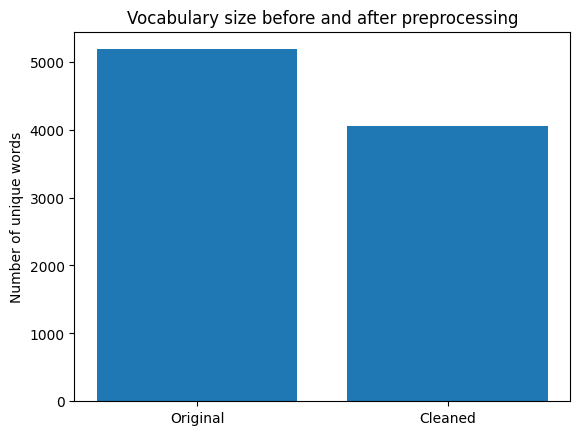

In [ ]:
# Visualising vocabulary reduction
original_words = set(re.findall(r"\b\w+\b", " ".join(df["text"].str.lower())))
clean_words = set(" ".join(df["clean_text"]).split())
print("Unique words before cleaning:", len(original_words))
print("Unique words after cleaning:", len(clean_words))
plt.bar(["Original", "Cleaned"], [len(original_words), len(clean_words)])
plt.title("Vocabulary size before and after preprocessing")
plt.ylabel("Number of unique words")
plt.show()

In [ ]:
#Tokenization — word, subword and character
from transformers import AutoTokenizer
bert_tokenizer = AutoTokenizer.from_pretrained("bert-base-uncased")
sentence = df["text"].iloc[0]
print("Review:", sentence)
print("\nWord tokens:", sentence.split())
print("\nBERT subword tokens:", bert_tokenizer.tokenize(sentence))
print("\nFirst 100 character tokens:", list(sentence[:100]))

config.json:   0%|          | 0.00/570 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/48.0 [00:00<?, ?B/s]

vocab.txt:   0%|          | 0.00/232k [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/466k [00:00<?, ?B/s]

Review: So there is no way for me to plug it in here in the US unless I go by a converter.

Word tokens: ['So', 'there', 'is', 'no', 'way', 'for', 'me', 'to', 'plug', 'it', 'in', 'here', 'in', 'the', 'US', 'unless', 'I', 'go', 'by', 'a', 'converter.']

BERT subword tokens: ['so', 'there', 'is', 'no', 'way', 'for', 'me', 'to', 'plug', 'it', 'in', 'here', 'in', 'the', 'us', 'unless', 'i', 'go', 'by', 'a', 'convert', '##er', '.']

First 100 character tokens: ['S', 'o', ' ', 't', 'h', 'e', 'r', 'e', ' ', 'i', 's', ' ', 'n', 'o', ' ', 'w', 'a', 'y', ' ', 'f', 'o', 'r', ' ', 'm', 'e', ' ', 't', 'o', ' ', 'p', 'l', 'u', 'g', ' ', 'i', 't', ' ', 'i', 'n', ' ', 'h', 'e', 'r', 'e', ' ', 'i', 'n', ' ', 't', 'h', 'e', ' ', 'U', 'S', ' ', 'u', 'n', 'l', 'e', 's', 's', ' ', 'I', ' ', 'g', 'o', ' ', 'b', 'y', ' ', 'a', ' ', 'c', 'o', 'n', 'v', 'e', 'r', 't', 'e', 'r', '.']


In [ ]:
encoded = bert_tokenizer(sentence, return_tensors="pt", truncation=True, max_length=128)
tokens = bert_tokenizer.convert_ids_to_tokens(encoded["input_ids"][0])
print("Tokens including special tokens:", tokens)

Tokens including special tokens: ['[CLS]', 'so', 'there', 'is', 'no', 'way', 'for', 'me', 'to', 'plug', 'it', 'in', 'here', 'in', 'the', 'us', 'unless', 'i', 'go', 'by', 'a', 'convert', '##er', '.', '[SEP]']


In [ ]:
# Bag-of-Words and TF-IDF
from sklearn.feature_extraction.text import CountVectorizer, TfidfVectorizer

# Use real cleaned reviews. These vectors are useful for exploration even without labels.
texts = df["clean_text"].replace("", np.nan).dropna()
bow = CountVectorizer(max_features=5000)
bow_matrix = bow.fit_transform(texts)
tfidf = TfidfVectorizer(max_features=5000)
tfidf_matrix = tfidf.fit_transform(texts)
print("Bag-of-Words matrix shape:", bow_matrix.shape)
print("TF-IDF matrix shape:", tfidf_matrix.shape)
print("First 20 vocabulary terms:", bow.get_feature_names_out()[:20])

Bag-of-Words matrix shape: (2721, 4030)
TF-IDF matrix shape: (2721, 4030)
First 20 vocabulary terms: ['aailiyah' 'abandon' 'abhor' 'ability' 'able' 'abound' 'abroad'
 'absolute' 'absolutel' 'absolutely' 'absolutley' 'abstruse' 'abysmal'
 'ac' 'academy' 'accent' 'accept' 'acceptable' 'access' 'accessable']


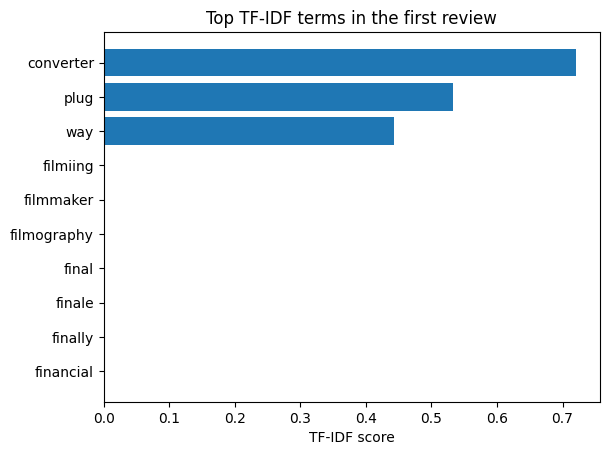

In [ ]:
# Show highest TF-IDF terms in the first review
feature_names = tfidf.get_feature_names_out()
first_scores = tfidf_matrix[0].toarray().ravel()
top_idx = first_scores.argsort()[-10:][::-1]
plt.barh(feature_names[top_idx][::-1], first_scores[top_idx][::-1])
plt.title("Top TF-IDF terms in the first review")
plt.xlabel("TF-IDF score")
plt.show()

In [ ]:
# Word embeddings with BERT
import torch
from transformers import AutoModel

embedding_tokenizer = AutoTokenizer.from_pretrained("bert-base-uncased")
embedding_model = AutoModel.from_pretrained("bert-base-uncased")
embedding_model.eval()
review = df["text"].iloc[0]
inputs = embedding_tokenizer(review, return_tensors="pt", truncation=True, max_length=128)
with torch.no_grad():
    outputs = embedding_model(**inputs)
# Average token vectors to create one vector for the review
review_embedding = outputs.last_hidden_state.mean(dim=1).squeeze().numpy()
print("Embedding shape:", review_embedding.shape)
print("First 10 values:", review_embedding[:10])

model.safetensors: reconstructing file:   0%|          |  0.00B /  440MB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

[transformers] BertModel LOAD REPORT from: bert-base-uncased
Key                                        | Status     |  | 
-------------------------------------------+------------+--+-
cls.seq_relationship.bias                  | UNEXPECTED |  | 
cls.predictions.bias                       | UNEXPECTED |  | 
cls.predictions.transform.dense.bias       | UNEXPECTED |  | 
cls.predictions.transform.LayerNorm.weight | UNEXPECTED |  | 
cls.seq_relationship.weight                | UNEXPECTED |  | 
cls.predictions.transform.dense.weight     | UNEXPECTED |  | 
cls.predictions.transform.LayerNorm.bias   | UNEXPECTED |  | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.


Embedding shape: (768,)
First 10 values: [ 0.29603145 -0.11516599  0.12863275  0.04121235  0.38802567 -0.44092864
  0.17576092  0.60775506  0.12596776 -0.07878555]


Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

[transformers] BertModel LOAD REPORT from: bert-base-uncased
Key                                        | Status     |  | 
-------------------------------------------+------------+--+-
cls.seq_relationship.bias                  | UNEXPECTED |  | 
cls.predictions.bias                       | UNEXPECTED |  | 
cls.predictions.transform.dense.bias       | UNEXPECTED |  | 
cls.predictions.transform.LayerNorm.weight | UNEXPECTED |  | 
cls.seq_relationship.weight                | UNEXPECTED |  | 
cls.predictions.transform.dense.weight     | UNEXPECTED |  | 
cls.predictions.transform.LayerNorm.bias   | UNEXPECTED |  | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.


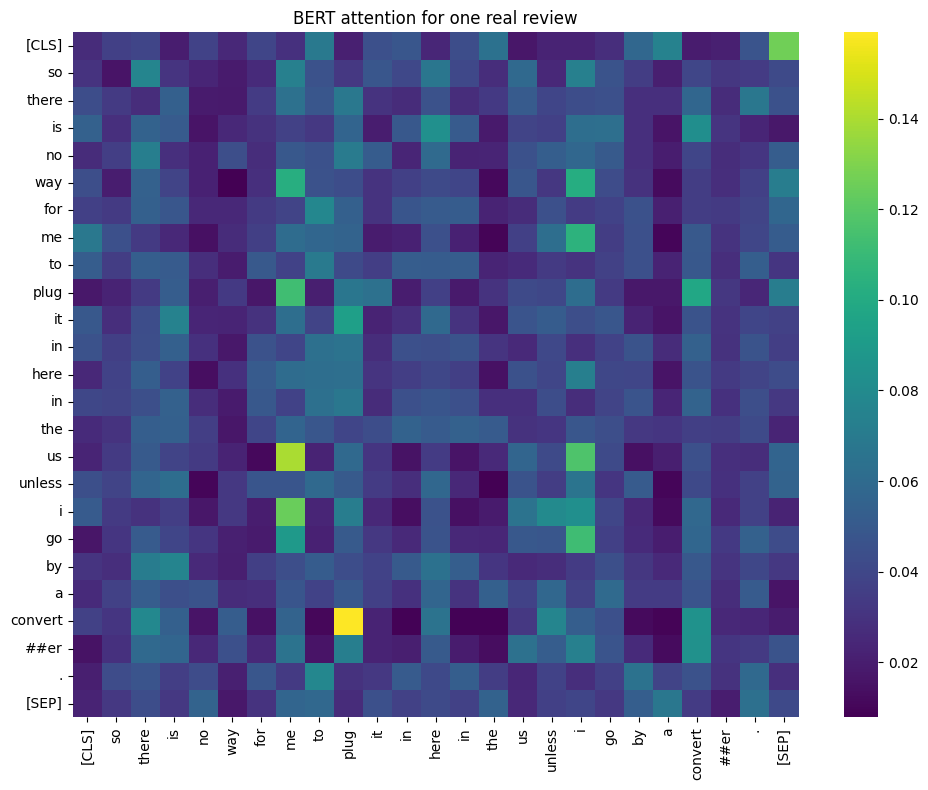

In [ ]:
# Transformer attention visualisation
attention_model = AutoModel.from_pretrained("bert-base-uncased", output_attentions=True)
attention_model.eval()
review = df["text"].iloc[0]
inputs = bert_tokenizer(review, return_tensors="pt", truncation=True, max_length=30)
with torch.no_grad():
    output = attention_model(**inputs)
tokens = bert_tokenizer.convert_ids_to_tokens(inputs["input_ids"][0])
# First transformer layer and first attention head
attention = output.attentions[0][0, 0].cpu().numpy()
plt.figure(figsize=(10, 8))
sns.heatmap(attention, xticklabels=tokens, yticklabels=tokens, cmap="viridis")
plt.title("BERT attention for one real review")
plt.xticks(rotation=90)
plt.yticks(rotation=0)
plt.tight_layout()
plt.show()

Sentiment analysis with a pretrained model (inference only)
Because the dataset has no sentiment labels, this step uses an already-trained sentiment model to predict sentiment for sample reviews. These are model predictions, not ground-truth labels, and must not be used to claim evaluation accuracy.

In [ ]:
from transformers import pipeline

sentiment_pipeline = pipeline(
    "sentiment-analysis",
    model="distilbert-base-uncased-finetuned-sst-2-english"
)

for review in df["text"].head(5):
    print("Review:", review[:250])
    print("Prediction:", sentiment_pipeline(review[:512])[0])
    print()

config.json:   0%|          | 0.00/629 [00:00<?, ?B/s]

model.safetensors: reconstructing file:   0%|          |  0.00B /  268MB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/104 [00:00<?, ?it/s]

tokenizer_config.json:   0%|          | 0.00/48.0 [00:00<?, ?B/s]

vocab.txt:   0%|          | 0.00/232k [00:00<?, ?B/s]

Review: So there is no way for me to plug it in here in the US unless I go by a converter.
Prediction: {'label': 'NEGATIVE', 'score': 0.9994086027145386}

Review: Good case, Excellent value.
Prediction: {'label': 'POSITIVE', 'score': 0.9998685121536255}

Review: Great for the jawbone.
Prediction: {'label': 'POSITIVE', 'score': 0.9997796416282654}

Review: Tied to charger for conversations lasting more than 45 minutes.MAJOR PROBLEMS!!
Prediction: {'label': 'NEGATIVE', 'score': 0.9994041919708252}

Review: The mic is great.
Prediction: {'label': 'POSITIVE', 'score': 0.9998689889907837}



In [ ]:
## 9. Named Entity Recognition (NER)
from spacy import displacy

review = df["text"].iloc[0]
doc = nlp(review)
for ent in doc.ents:
    print(ent.text, "→", ent.label_)
displacy.render(doc, style="ent", jupyter=True)

US → GPE
